# wave prediction with mslp and wind

this notebook-style script:
- runs data preprocessing for mslp and 10 m wind (u, v)
- prepares tensors for deep learning
- trains a transformer-based model
- reloads the trained model and makes predictions

## imports and paths

In [1]:
%load_ext autoreload
%autoreload 2
#this is to avoid to restart the kernel everytime we change our helper functions e.g. utils ...

In [2]:
from pathlib import Path
from datetime import datetime

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import torch
from utils import compute_skill_metrics_for_dfs
import storm_detection

# import project modules
from train_atmoswave_transformer import AtmosWaveTransformer, train_and_save_model
from predict_atmoswave_transformer import load_model_checkpoint, predict_wave
from scipy.stats import pearsonr, spearmanr
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, mean_squared_error, r2_score

## helper functions

In [ ]:
import pandas as pd


mslp = pd.read_parquet(
    "../data/stdanom_mslp_data.parquet"
)

wind = pd.read_parquet(
    "../data/stdanom_windU_data.parquet"
)

print(mslp.columns[:10].tolist())
print(wind.columns[:10].tolist())

### load the saved performance docs, and visulaise

In [18]:
skill_file = Path( "../results/skill_metrics/" "prediction_skill_block_bootstrap.parquet" ) 
skill = pd.read_parquet(skill_file) 
print(skill.shape) 
print(skill.columns.tolist()) 
skill.head()

(150, 15)
['date', 'model', 'poi', 'window_hours', 'seed', 'variable', 'metric', 'ci95_lower', 'bootstrap_median', 'ci95_upper', 'bootstrap_mean', 'bootstrap_std', 'n_observations', 'n_blocks', 'block_hours']


,date,model,poi,window_hours,seed,variable,metric,ci95_lower,bootstrap_median,ci95_upper,bootstrap_mean,bootstrap_std,n_observations,n_blocks,block_hours
0,2026_10_13,transformer,SEE,6,42,hs,bias,0.037318,0.042264,0.047235,0.042252,0.002554,140112,834,168
1,2026_10_13,transformer,SEE,6,42,hs,mae,0.139626,0.142369,0.145457,0.142490,0.001503,140112,834,168
2,2026_10_13,transformer,SEE,6,42,hs,r2,0.942954,0.947264,0.951264,0.947230,0.002174,140112,834,168
3,2026_10_13,transformer,SEE,6,42,hs,rmse,0.185632,0.190146,0.194876,0.190319,0.002335,140112,834,168
4,2026_10_13,transformer,SEE,6,42,hs,spearman,0.952362,0.955931,0.958955,0.955915,0.001627,140112,834,168


In [23]:
seed_summary = (
    skill
    .groupby(
        [
            "model",
            "poi",
            "window_hours",
            "variable",
            "metric",
        ],
        as_index=False,
    )
    .agg(
        mean_across_seeds=(
            "bootstrap_mean",
            "mean",
        ),
        std_across_seeds=(
            "bootstrap_mean",
            lambda x: x.std(ddof=1),
        ),
        n_seeds=(
            "seed",
            "nunique",
        ),
    )
)

In [24]:
seed_summary["reported_value"] = seed_summary.apply(
    lambda row: (
        f"{row['mean_across_seeds']:.3f} "
        f"± {row['std_across_seeds']:.3f}"
    ),
    axis=1,
)

In [29]:
seed_summary.loc[(seed_summary['variable']=='hs')&(seed_summary['metric']=='spearman')]

,model,poi,window_hours,variable,metric,mean_across_seeds,std_across_seeds,n_seeds,reported_value
4,mlp,SEE,6,hs,spearman,0.960543,NaN,1,0.961 ± nan
19,transformer,SEE,6,hs,spearman,0.954565,0.002077,3,0.955 ± 0.002
34,transformer,SEE,12,hs,spearman,0.967836,0.000612,3,0.968 ± 0.001
49,transformer,SEE,24,hs,spearman,0.974053,0.003533,3,0.974 ± 0.004


### define the location and window size

In [3]:
poi = 'SEE' # (adjust if you use a different file or location) SEE, OFD, NST -- ELB is relative further offshore from Wremen, so we consider OFD
window = ['06', '12', '24'][0]  #06, 12, or 24
w_name = f'w{window}'
run_date = '2026_10_13'
seed = 42

In [26]:
print(f'selected: {run_date} {poi} {window} {w_name} {seed}')

selected: 2026_10_13 SEE 06 w06 42


## data directories

In [5]:
# base data directory used in preprocessing script
data_dir = Path("../data")

# wave data 
wave_path = data_dir / "prepared_wave" / f"wave_data_processed_{poi}.parquet"

# paths to prepared tensor files
full_tensor_path = data_dir / "prepared_tensors" / f"wave_mslp_wind_tensors_{poi}_{w_name}.pt"

# directory where models will be saved
models_dir = Path("../models")
models_dir.mkdir(parents=True, exist_ok=True)

## step 1 -- tensor check before ML models

In [6]:
#load and inspect saved tensors
load_saved_tensors = False

In [7]:
if load_saved_tensors:
    print('loading tensors!!')
    ckpt = torch.load(full_tensor_path, map_location="cpu", weights_only=True)
    
    X_mslp  = ckpt["X_mslp"]
    X_windU = ckpt["X_windU"]
    X_windV = ckpt["X_windV"]
    y       = ckpt["y"]
    y_dates = ckpt["y_dates"]  # list of strings

    # if any array has a different number of rows. the program raises an AssertionError and stops execution!!
    assert X_mslp.shape[0] == X_windU.shape[0] == X_windV.shape[0] == y.shape[0], "Row count mismatch! "
    
    X_mslp.shape, X_windU.shape, X_windV.shape, y.shape, 
    # for 12 hours it is [666204, 12, 2400], for 24: , and for 6:666192, 24, 2400

## lets load saved models

In [14]:
print(f'selected: {poi} {window} {w_name}')

selected: SEE 24 w24


In [15]:
ckpt = torch.load(
    f"../models/{run_date}_atmoswave_transformer_{poi}_{w_name}_sd{seed:04d}.pt",
    map_location="cpu",
)

/tmp/ipykernel_3394364/1260370339.py:1: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  ckpt = torch.load(


In [16]:
model = AtmosWaveTransformer(
    T=ckpt["hyperparams"]["T"],
    F1=ckpt["hyperparams"]["F1"],
    F2=ckpt["hyperparams"]["F2"],
    F3=ckpt["hyperparams"]["F3"],
    d_model=ckpt["hyperparams"]["d_model"],
    nhead=ckpt["hyperparams"]["nhead"],
    num_layers=ckpt["hyperparams"]["num_layers"],
    d_ff=ckpt["hyperparams"]["d_ff"],
    dropout=ckpt["hyperparams"]["dropout"],
    output_dim=ckpt["hyperparams"]["output_dim"],
)

model.load_state_dict(ckpt["model_state_dict"])

n_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print(f"trainable parameters: {n_params:,}")
print(f"trainable parameters: {n_params / 1e6:.2f} million")

trainable parameters: 731,076
trainable parameters: 0.73 million


/sw/spack-levante/miniforge3-24.11.3-2-Linux-x86_64-hbhytx/lib/python3.12/site-packages/torch/nn/modules/transformer.py:379: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  warnings.warn(


In [17]:
import torch
from train_atmoswave_baselineMLP import AtmosWaveMLP


ckpt = torch.load(
    (
        f"../models/2026_10_15_atmoswave_baselineMLP_SEE_w24_sd0042.pt"
    ),
    map_location="cpu",
    weights_only=False,
)

input_dims = ckpt["input_dimensions"]
hyperparams = ckpt["hyperparameters"]

model = AtmosWaveMLP(
    input_dim=input_dims["input_dim"],
    hidden_dim=hyperparams["hidden_dim"],
    num_layers=hyperparams["num_layers"],
    dropout=hyperparams["dropout"],
    output_dim=input_dims["output_dim"],
)

model.load_state_dict(
    ckpt["model_state_dict"]
)

n_params = sum(
    parameter.numel()
    for parameter in model.parameters()
    if parameter.requires_grad
)

print(f"trainable parameters: {n_params:,}")
print(f"trainable parameters: {n_params / 1e6:.2f} million")

trainable parameters: 19,728,900
trainable parameters: 19.73 million


## get predictions

In [30]:
poi = 'SEE' # (adjust if you use a different file or location) SEE, OFD, NST -- ELB is relative further offshore from Wremen, so we consider OFD
window = ['06', '12', '24'][2]  #06, 12, or 24
w_name = f'w{window}'
run_date = '2026_10_16'
seed = 42

In [31]:
print(f'selected: {run_date} {poi} {window} {w_name} {seed}')

selected: 2026_10_16 SEE 24 w24 42


In [34]:
predictions = pd.read_parquet(f'../results/{run_date}_atmoswaveT_predictions_{poi}_{w_name}_sd{seed:04d}.parquet')

# dfs for preidtioncs and hindcast
df_hcst = predictions.loc[:,['hs_obs', 't0_obs', 'thq_deg_obs']].rename(
    columns={'hs_obs': 'hs', 't0_obs': 't0', 'thq_deg_obs': 'thq_deg'})
df_pred = predictions.loc[:,['hs_pred', 't0_pred', 'thq_deg_pred']].rename(
    columns={'hs_pred': 'hs', 't0_pred': 't0', 'thq_deg_pred': 'thq_deg'})

In [35]:
compute_skill_metrics_for_dfs(df_hcst, df_pred)   # 24 hours  --- from above cell

,RMSE,Bias,MAE,R2,Spearman,NObs
hs,0.189039,-0.083123,0.124496,0.948169,0.977815,140256.0
t0,0.450833,-0.135593,0.305439,0.873836,0.929452,140256.0
thq_deg,25.816637,0.547695,8.535228,0.844079,0.955117,140256.0


In [13]:
compute_skill_metrics_for_dfs(df_hcst, df_pred)   # 24 hours  seed 43

,RMSE,Bias,MAE,R2,Spearman,NObs
hs,0.169310,0.001736,0.119072,0.958423,0.973763,140256.0
t0,0.436515,-0.050074,0.291218,0.881722,0.926215,140256.0
thq_deg,25.345472,0.953647,8.675223,0.849718,0.956979,140256.0


In [9]:
compute_skill_metrics_for_dfs(df_hcst, df_pred)   # 24 hours  seed 41

,RMSE,Bias,MAE,R2,Spearman,NObs
hs,0.226983,-0.088252,0.149982,0.925273,0.970816,140256.0
t0,0.464297,-0.119597,0.320176,0.866188,0.926800,140256.0
thq_deg,25.340439,-0.701028,8.725147,0.849778,0.956627,140256.0


In [86]:
compute_skill_metrics_for_dfs(df_hcst, df_pred)   # 24 hours

,RMSE,Bias,MAE,R2,Spearman,NObs
hs,0.189042,-0.083151,0.124508,0.948167,0.977814,140256.0
t0,0.450841,-0.135621,0.305448,0.873831,0.929451,140256.0
thq_deg,25.816811,0.547796,8.535217,0.844077,0.955116,140256.0


In [81]:
compute_skill_metrics_for_dfs(df_hcst, df_pred)   # 12 hours

,RMSE,Bias,MAE,R2,Spearman,NObs
hs,0.166016,0.004597,0.120192,0.960025,0.967386,140256.0
t0,0.495977,0.012146,0.328628,0.847304,0.901400,140256.0
thq_deg,28.416168,0.717804,10.193566,0.811098,0.943104,140256.0


In [77]:
compute_skill_metrics_for_dfs(df_hcst, df_pred)   # 6 hours

,RMSE,Bias,MAE,R2,Spearman,NObs
hs,0.190356,0.042081,0.142486,0.947444,0.956076,140256.0
t0,0.569423,0.056090,0.390696,0.798732,0.870239,140256.0
thq_deg,29.024973,0.648494,11.594258,0.802917,0.934222,140256.0


In [5]:
compute_skill_metrics_for_dfs(df_hcst, df_pred)  

,RMSE,Bias,MAE,R2,Spearman,NObs
hs,0.229932,-0.001287,0.162631,0.923319,0.955695,140256.0
t0,0.445710,0.006450,0.320245,0.876687,0.921450,140256.0
thq_deg,27.249506,-0.688779,9.240492,0.826291,0.951522,140256.0


In [39]:
# this is MLP predictions
predictions = pd.read_parquet(f'../results/2026_10_16_atmoswave_bMLP_predictions_SEE_w24_sd0043.parquet')
# 2026_10_15_atmoswave_bMLP_predictions_SEE_w24_sd0042 
#2026_10_15_atmoswave_bMLP_predictions_SEE_w24_sd0042
# 

# dfs for preidtioncs and hindcast
df_hcst = predictions.loc[:,['hs_obs', 't0_obs', 'thq_deg_obs']].rename(
    columns={'hs_obs': 'hs', 't0_obs': 't0', 'thq_deg_obs': 'thq_deg'})
df_pred = predictions.loc[:,['hs_pred', 't0_pred', 'thq_deg_pred']].rename(
    columns={'hs_pred': 'hs', 't0_pred': 't0', 'thq_deg_pred': 'thq_deg'})

FileNotFoundError: [Errno 2] No such file or directory: '../results/2026_10_16_atmoswave_bMLP_predictions_SEE_w24_sd0043.parquet'

In [38]:
compute_skill_metrics_for_dfs(df_hcst, df_pred)  

,RMSE,Bias,MAE,R2,Spearman,NObs
hs,0.229932,-0.001287,0.162631,0.923319,0.955695,140256.0
t0,0.445710,0.006450,0.320245,0.876687,0.921450,140256.0
thq_deg,27.249506,-0.688779,9.240492,0.826291,0.951522,140256.0


In [38]:
compute_skill_metrics_for_dfs(df_hcst, df_pred)  

,RMSE,Bias,MAE,R2,Spearman,NObs
hs,0.229932,-0.001287,0.162631,0.923319,0.955695,140256.0
t0,0.445710,0.006450,0.320245,0.876687,0.921450,140256.0
thq_deg,27.249506,-0.688779,9.240492,0.826291,0.951522,140256.0


### prediction scatter plots

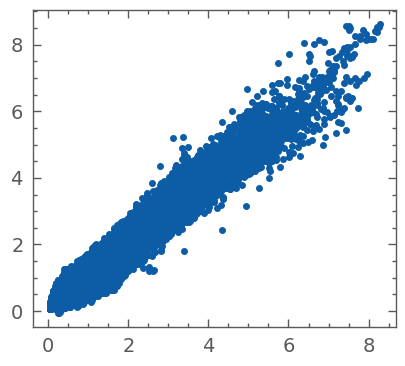

In [72]:
fig, axes = plt.subplots(1, 1, figsize=(2.2, 2), dpi=200)  
plt.plot(df_hcst['hs'], df_pred['hs'], '.')
plt.show()

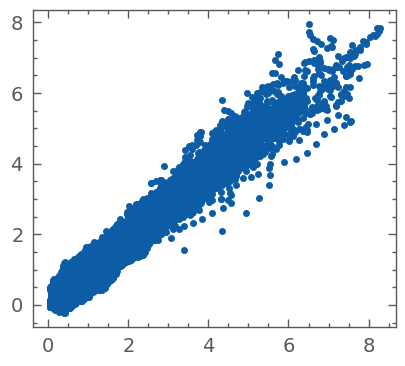

In [65]:
fig, axes = plt.subplots(1, 1, figsize=(2.2, 2), dpi=200)  
plt.plot(df_hcst['hs'], df_pred['hs'], '.')
plt.show()

### 7-day block bootstrap

In [8]:
n_boot = 1000
block_size = 24 * 7
var = 'hs'

obs = df_hcst[var].values
pred = df_pred[var].values

n_blocks = len(obs) // block_size

obs = obs[:n_blocks * block_size]
pred = pred[:n_blocks * block_size]

obs_blocks = obs.reshape(n_blocks, block_size)
pred_blocks = pred.reshape(n_blocks, block_size)

rmse_boot = []
mae_boot = []
bias_boot = []
r2_boot = []
rs_boot = []

for _ in range(n_boot):

    idx = np.random.randint(0, n_blocks, n_blocks)

    obs_bs = obs_blocks[idx].ravel()
    pred_bs = pred_blocks[idx].ravel()

    rmse_boot.append(
        np.sqrt(mean_squared_error(obs_bs, pred_bs))
    )

    mae_boot.append(
        mean_absolute_error(obs_bs, pred_bs)
    )

    bias_boot.append(
        np.mean(pred_bs - obs_bs)
    )

    r2_boot.append(
        r2_score(obs_bs, pred_bs)
    )

    rs_boot.append(
        spearmanr(obs_bs, pred_bs)[0]
    )


def stats(x):
    return {
        "mean": np.mean(x),
        "std": np.std(x),
        "ci95": np.percentile(x, [2.5, 97.5]),
        "median": np.percentile(x, 50)
    }


for name, metric in [
    ("RMSE", rmse_boot),
    ("MAE", mae_boot),
    ("Bias", bias_boot),
    ("R²", r2_boot),
    ("Rs", rs_boot)
]:
    s = stats(metric)

    print(
        f"{name}: "
        f"mean={s['mean']:.4f}, "
        f"std={s['std']:.4f}, "
        f"median={s['median']:.4f}, "
        f"95%CI=[{s['ci95'][0]:.4f}, {s['ci95'][1]:.4f}]"
    )

RMSE: mean=0.1796, std=0.0032, median=0.1796, 95%CI=[0.1734, 0.1860]
MAE: mean=0.1294, std=0.0017, median=0.1294, 95%CI=[0.1261, 0.1328]
Bias: mean=-0.0290, std=0.0025, median=-0.0291, 95%CI=[-0.0339, -0.0239]
R²: mean=0.9532, std=0.0018, median=0.9532, 95%CI=[0.9495, 0.9565]
Rs: mean=0.9607, std=0.0016, median=0.9607, 95%CI=[0.9573, 0.9637]


## visualise the 16 extreme wave-storm events

In [40]:
wam_wave_storms = storm_detection.detect_wave_storms(
    df_hcst.loc[:, ['hs','t0','thq_deg']], 
    freq_hours = 1.0,
    threshold1= 1.48,
    threshold2 = 2.74,
    min_duration= 6,
    min_gap = 48
)

In [41]:
wam_wave_storms['storm_power'] = wam_wave_storms['duration_hours'] * wam_wave_storms['max_hs']**2

idx = (
    wam_wave_storms
    .groupby(wam_wave_storms['start_time'].dt.year)['storm_power']
    .idxmax()
)

In [43]:
wam_wave_storms.loc[idx].sort_values('start_time').loc[:,:]

,start_time,end_time,duration_hours,max_hs,time_max_hs,mean_hs,mean_t0,mean_thq,storm_id,storm_power
5,2008-02-21 13:00:00,2008-03-07 00:00:00,347.0,7.380053,2008-03-01 13:00:00,2.797606,6.004509,None,6,18899.415943
26,2009-09-30 20:00:00,2009-10-05 11:00:00,111.0,5.766103,2009-10-04 05:00:00,2.978107,6.181708,None,27,3690.521347
41,2010-10-18 16:00:00,2010-10-26 05:00:00,181.0,5.044798,2010-10-24 09:00:00,2.624688,5.728148,None,42,4606.447376
60,2011-12-02 08:00:00,2011-12-21 15:00:00,463.0,7.302068,2011-12-09 08:00:00,2.447299,5.727572,None,61,24687.249935
62,2012-01-02 15:00:00,2012-01-09 02:00:00,155.0,6.354467,2012-01-05 16:00:00,3.729437,6.800479,None,63,6258.784866
90,2013-11-28 08:00:00,2013-12-10 00:00:00,280.0,8.268929,2013-12-06 07:00:00,3.072735,6.209279,None,91,19145.049133
102,2014-12-09 19:00:00,2014-12-25 22:00:00,387.0,6.471594,2014-12-20 18:00:00,2.788785,5.803279,None,103,16208.153881
104,2015-01-08 19:00:00,2015-01-18 12:00:00,233.0,6.322485,2015-01-11 14:00:00,3.010238,5.895739,None,105,9313.900887
132,2016-12-22 22:00:00,2016-12-28 08:00:00,130.0,7.662793,2016-12-27 03:00:00,3.242290,6.390260,None,133,7633.390884
134,2017-01-11 00:00:00,2017-01-15 16:00:00,112.0,7.954803,2017-01-13 19:00:00,4.066069,7.587887,None,135,7087.236389


/work/gg0303/g260244/metascales/wave-forecasts/codes/storm_detection.py:273: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax1.set_xticklabels(labels)
/work/gg0303/g260244/metascales/wave-forecasts/codes/storm_detection.py:273: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax1.set_xticklabels(labels)
/work/gg0303/g260244/metascales/wave-forecasts/codes/storm_detection.py:273: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax1.set_xticklabels(labels)
/work/gg0303/g260244/metascales/wave-forecasts/codes/storm_detection.py:273: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax1.set_xticklabels(labels)
/work/gg0303/g260244/metascales/wave-forecasts/codes/storm_d

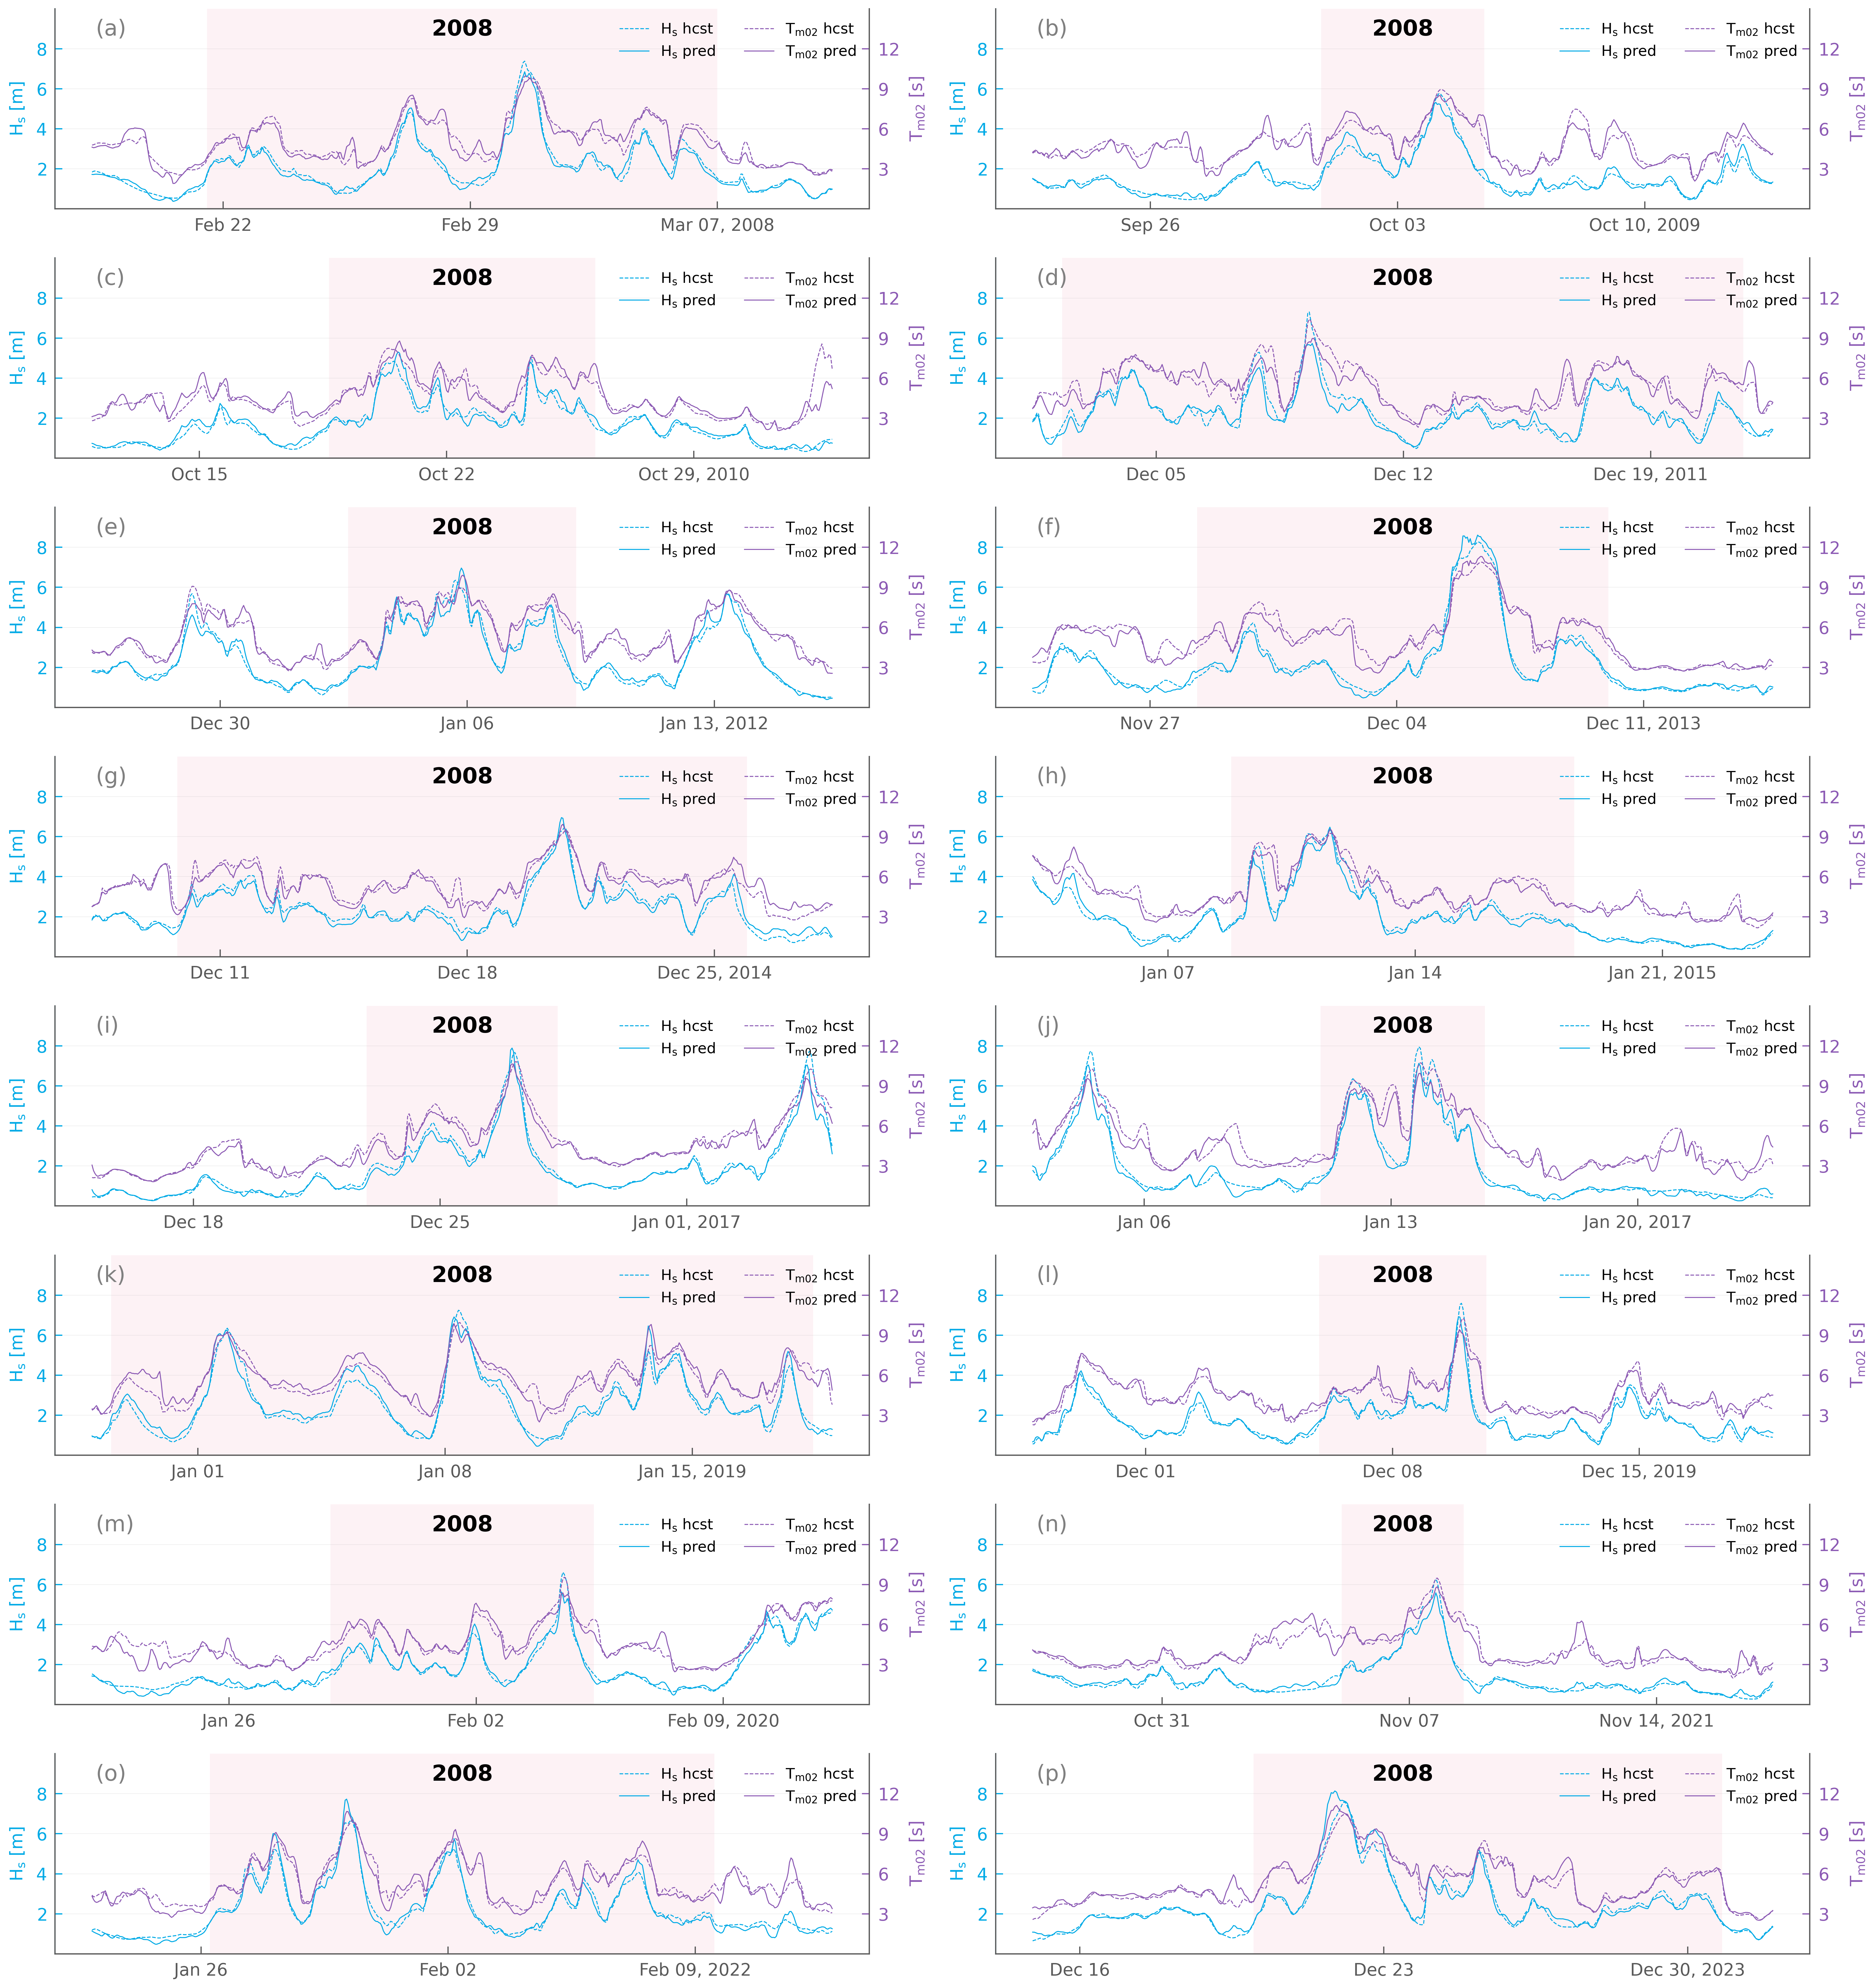

In [50]:
fig, axes = plt.subplots(8, 2, figsize=(10.8, 11.439), dpi=600)     #7.2 6.5  --10.8, 12 works ...
storm_detection.plot_storm(df_hcst,df_pred, '2008-02-21 13:00:00','2008-03-07 00:00:00', year = '2008', ax=axes[0,0], fig_num="(a)")
storm_detection.plot_storm(df_hcst,df_pred, '2009-09-30 20:00:00','2009-10-05 11:00:00', year = '2008', ax=axes[0,1], fig_num="(b)")
storm_detection.plot_storm(df_hcst,df_pred, '2010-10-18 16:00:00','2010-10-26 05:00:00', year = '2008', ax=axes[1,0], fig_num="(c)")
storm_detection.plot_storm(df_hcst,df_pred, '2011-12-02 08:00:00','2011-12-21 15:00:00', year = '2008', ax=axes[1,1], fig_num="(d)")
storm_detection.plot_storm(df_hcst,df_pred, '2012-01-02 15:00:00','2012-01-09 02:00:00', year = '2008', ax=axes[2,0], fig_num="(e)")
storm_detection.plot_storm(df_hcst,df_pred, '2013-11-28 08:00:00','2013-12-10 00:00:00', year = '2008', ax=axes[2,1], fig_num="(f)")
storm_detection.plot_storm(df_hcst,df_pred, '2014-12-09 19:00:00','2014-12-25 22:00:00', year = '2008', ax=axes[3,0], fig_num="(g)")
storm_detection.plot_storm(df_hcst,df_pred, '2015-01-08 19:00:00','2015-01-18 12:00:00', year = '2008', ax=axes[3,1], fig_num="(h)")
storm_detection.plot_storm(df_hcst,df_pred, '2016-12-22 22:00:00','2016-12-28 08:00:00', year = '2008', ax=axes[4,0], fig_num="(i)")
storm_detection.plot_storm(df_hcst,df_pred, '2017-01-11 00:00:00','2017-01-15 16:00:00', year = '2008', ax=axes[4,1], fig_num="(j)")
storm_detection.plot_storm(df_hcst,df_pred, '2018-12-29 13:00:00','2019-01-18 10:00:00', year = '2008', ax=axes[5,0], fig_num="(k)")
storm_detection.plot_storm(df_hcst,df_pred, '2019-12-05 22:00:00','2019-12-10 16:00:00', year = '2008', ax=axes[5,1], fig_num="(l)")
storm_detection.plot_storm(df_hcst,df_pred, '2020-01-28 21:00:00','2020-02-05 08:00:00', year = '2008', ax=axes[6,0], fig_num="(m)")
storm_detection.plot_storm(df_hcst,df_pred, '2021-11-05 02:00:00','2021-11-08 13:00:00', year = '2008', ax=axes[6,1], fig_num="(n)")
storm_detection.plot_storm(df_hcst,df_pred, '2022-01-26 06:00:00','2022-02-09 13:00:00', year = '2008', ax=axes[7,0], fig_num="(o)")
storm_detection.plot_storm(df_hcst,df_pred, '2023-12-20 00:00:00','2023-12-30 19:00:00', year = '2008', ax=axes[7,1], fig_num="(p)")
# axes[7,1].set_visible(False)
fig.tight_layout()
# fig.savefig(f'../results/figures/fig_wave_storm-predictions.png', dpi=600)
plt.show()

In [ ]:
stop!

## misc

In [8]:
compute_skill_metrics_for_dfs(df_hcst, df_pred)  #--- for 24

,RMSE,Bias,MAE,R2,Spearman,NObs
hs,0.179650,-0.029054,0.129395,0.953189,0.960712,140256.0
t0,0.523498,-0.048405,0.352179,0.829888,0.887219,140256.0
thq_deg,29.087517,-0.212596,10.811606,0.802067,0.937294,140256.0


In [18]:
compute_skill_metrics_for_dfs(df_hcst, df_pred)  #--- for 24

,RMSE,Bias,MAE,R2,Spearman,NObs
hs,0.189042,-0.083151,0.124508,0.948167,0.977814,140256.0
t0,0.450841,-0.135621,0.305448,0.873831,0.929451,140256.0
thq_deg,25.816811,0.547796,8.535217,0.844077,0.955116,140256.0


In [ ]:
compute_skill_metrics_for_dfs(df_hcst, df_pred) #--- for 12

In [ ]:
compute_skill_metrics_for_dfs(df_hcst, df_pred) #--- for 6

   *skill metrics of the model trained on 24.03.2026 as a comparison  -->*
<div align="left">

| Variable | RMSE | Bias | MAE | R² | Spearman | NObs |
|:---------|:-----|:------|:------|:------|:----------|:---------|
| hs       | 0.208028 | -0.006990 | 0.147265 | 0.937232 | 0.953484 | 140,248 |
| t0       | 0.587284 | 0.051014  | 0.398005 | 0.785879 | 0.870677 | 140,248 |
| thq_deg  | 29.547848 | 1.479497 | 11.835914 | 0.795693 | 0.933123 | 140,248 |

</div>

##### Bias and MAE error calculations for angles in degrees

In [ ]:
df_pred['thq_deg'].max()

In [ ]:
def angular_difference_deg(pred, obs):
    diff = pred - obs
    # wrap to [-180, 180)
    diff = (diff + 180) % 360 - 180
    return diff

In [ ]:
angular_difference_deg(df_pred['thq_deg'], df_hcst['thq_deg']).mean()

In [ ]:
np.abs(angular_difference_deg(df_pred['thq'], df_hcst['thq'])).mean()

In [ ]:
stop!